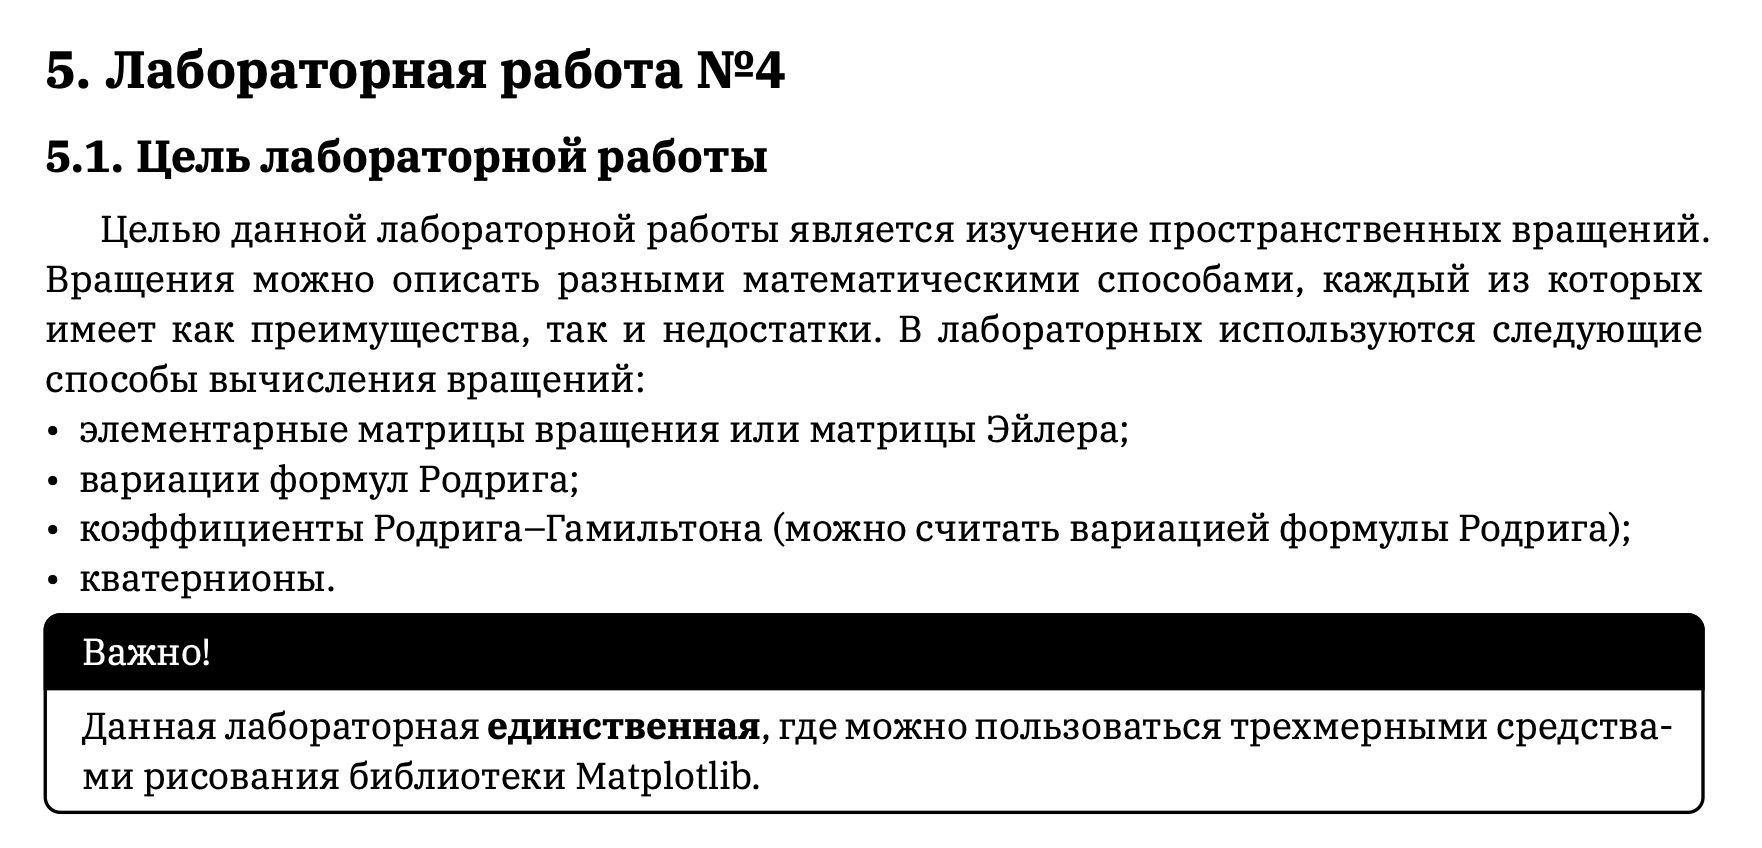

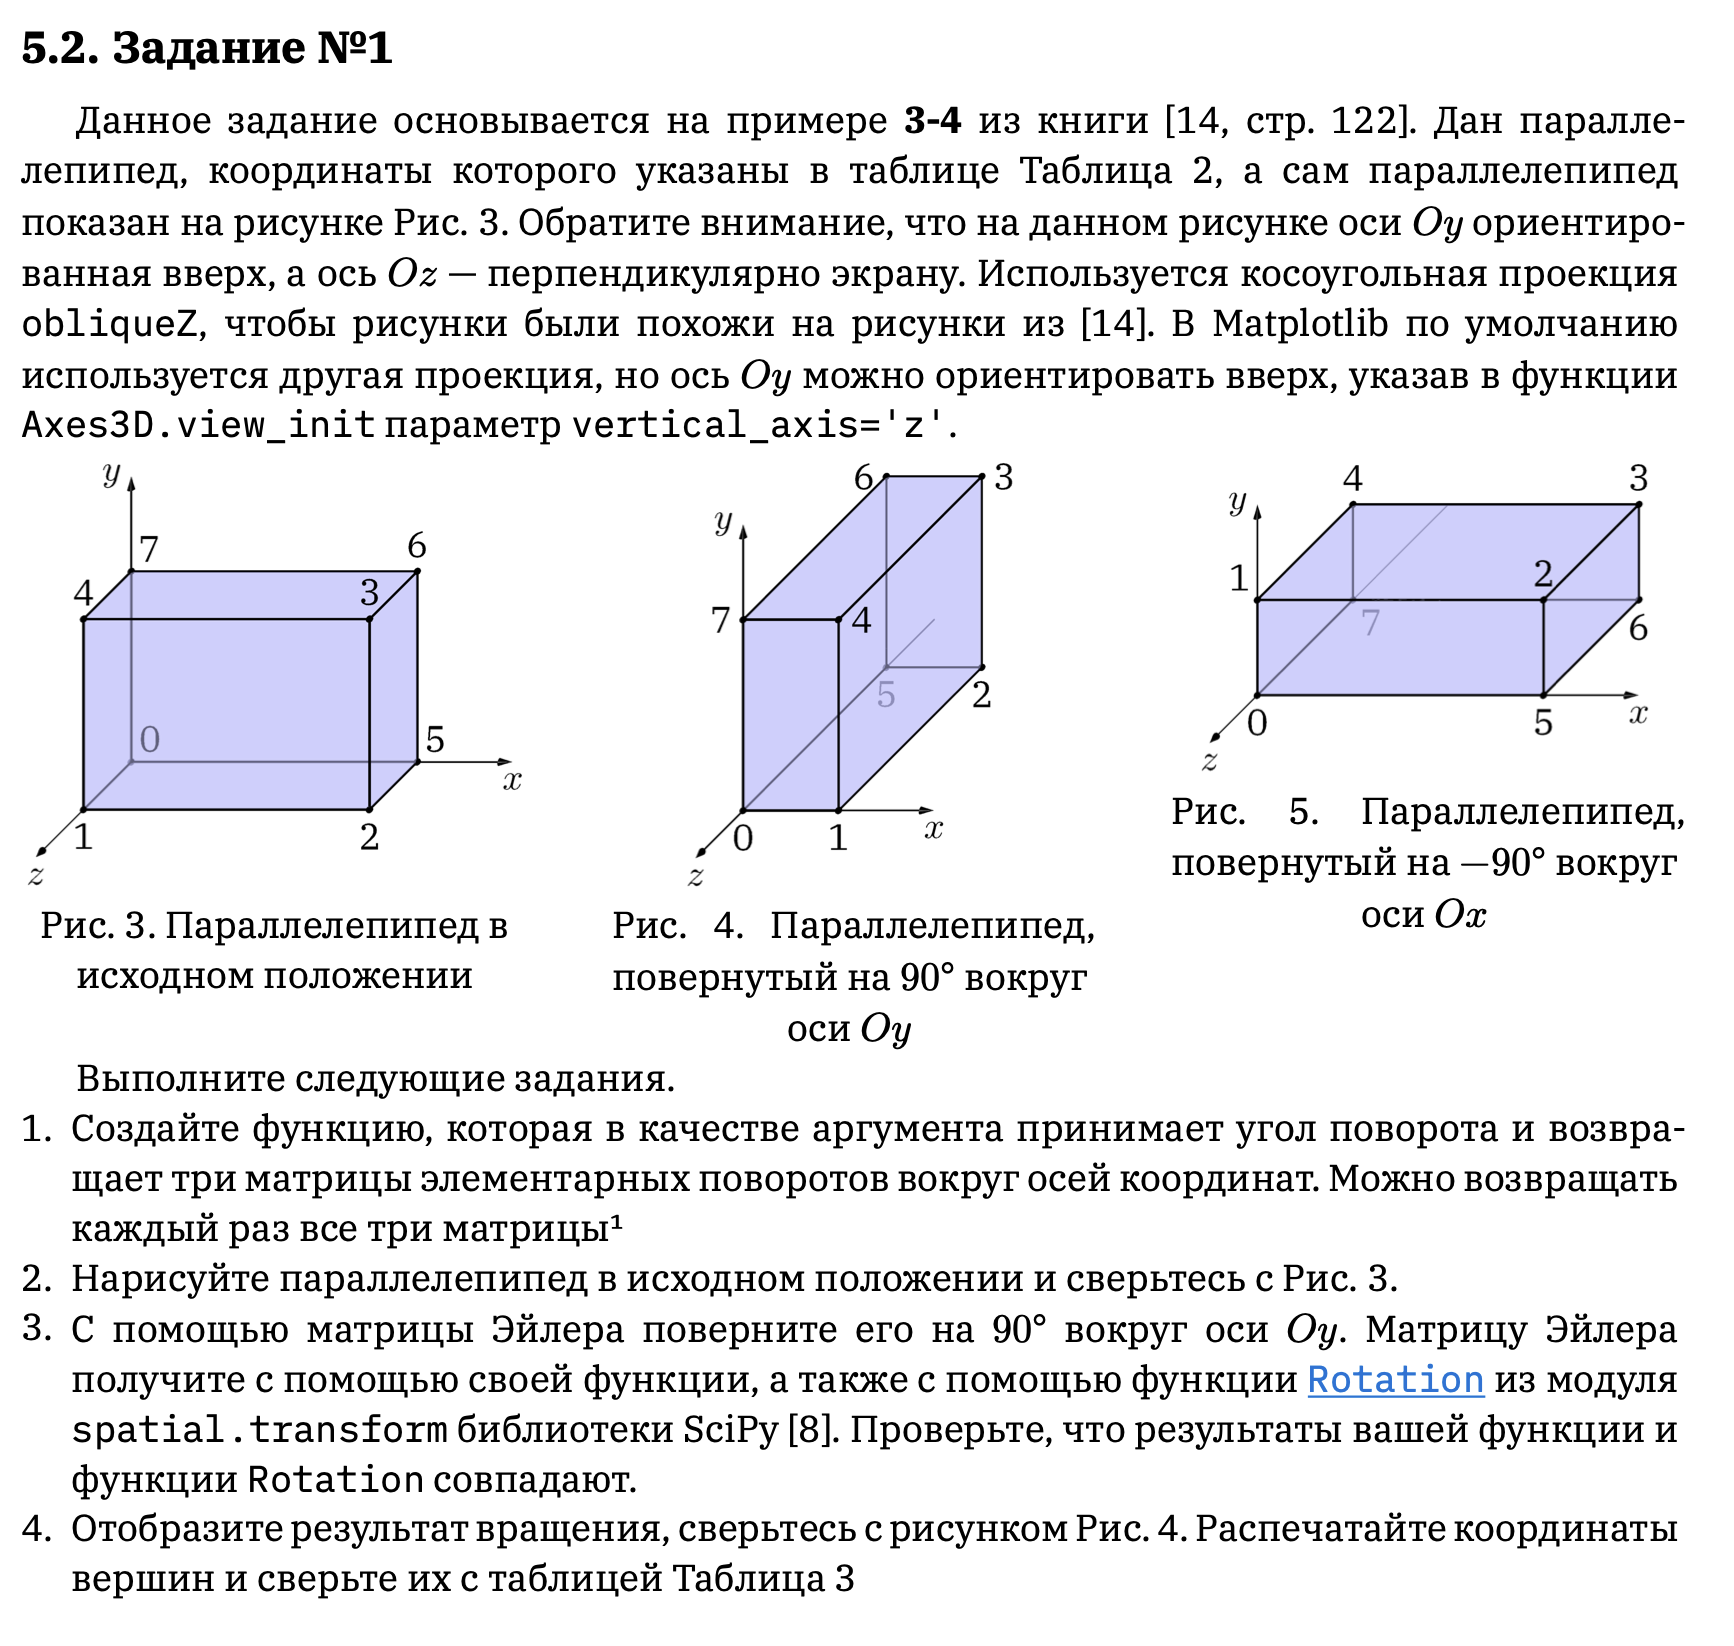

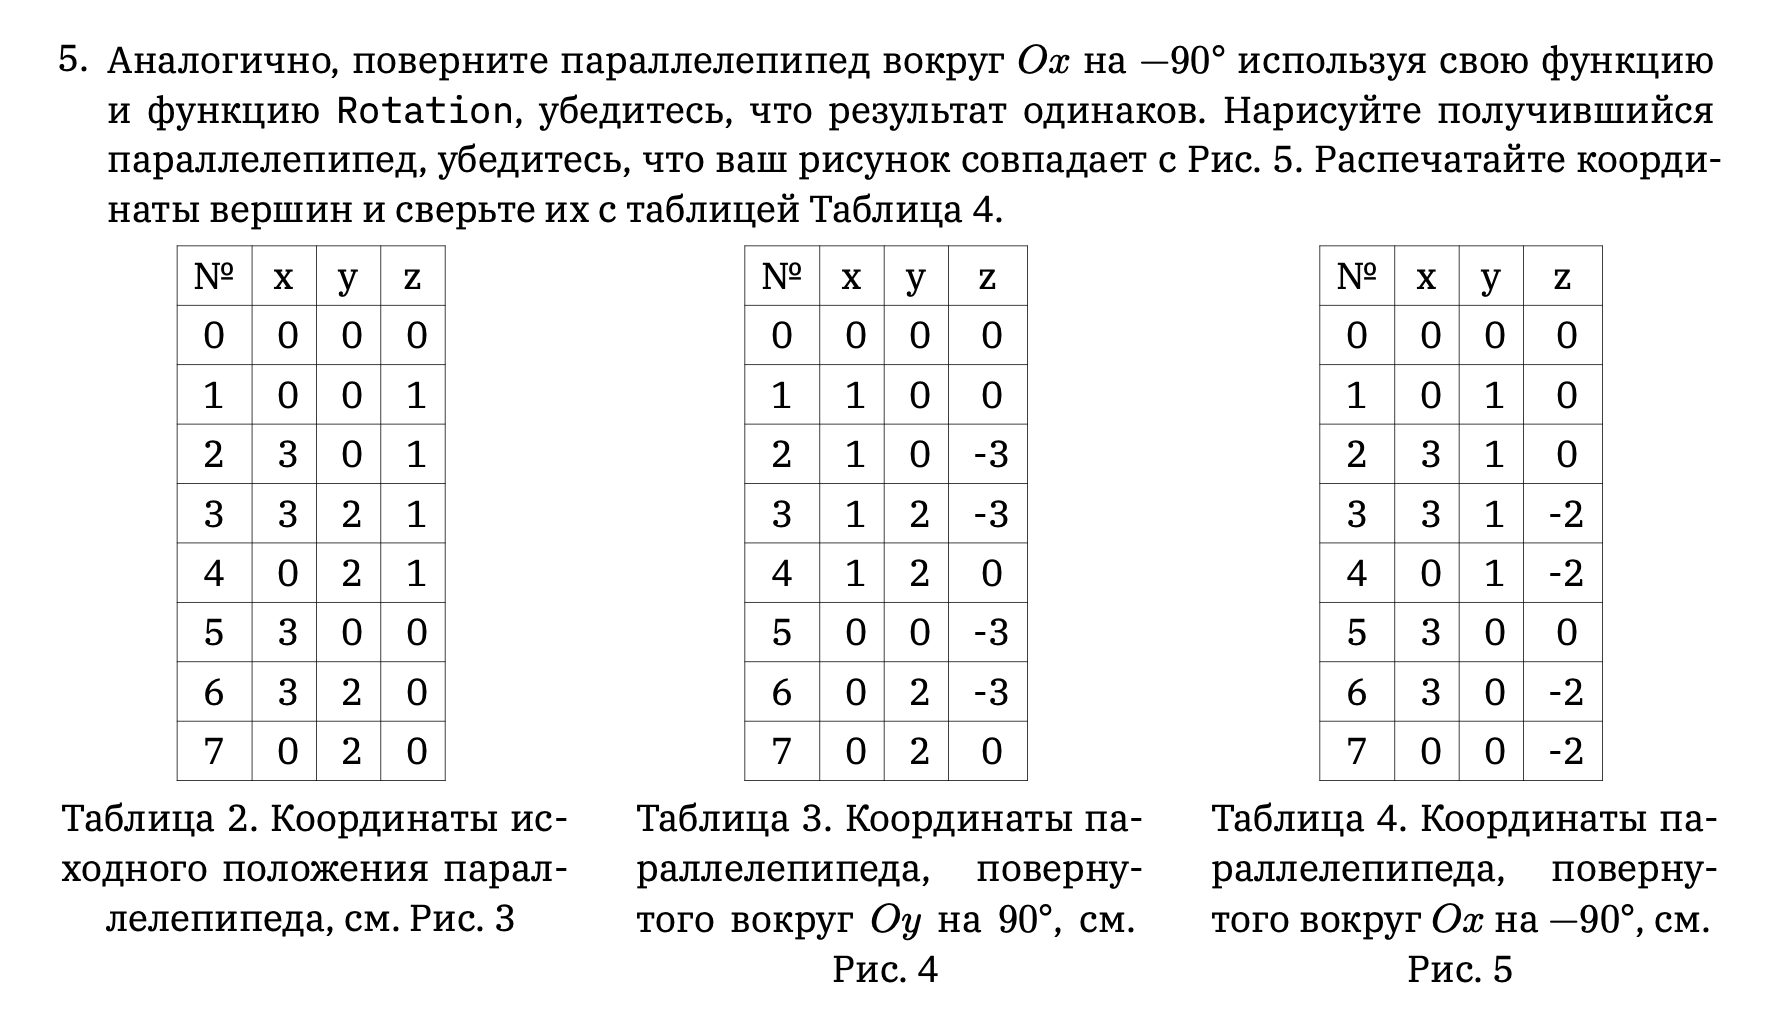

In [2]:
# 1. Функция, возвращающая матрицы элементарных поворотов

def rotation_matrices(angle_deg):
    """
    Возвращает три матрицы поворота (Rx, Ry, Rz) для заданного угла в градусах.
    """
    angle = np.radians(angle_deg)
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(angle), -np.sin(angle)],
        [0, np.sin(angle),  np.cos(angle)]
    ])
    Ry = np.array([
        [ np.cos(angle), 0, np.sin(angle)],
        [0, 1, 0],
        [-np.sin(angle), 0, np.cos(angle)]
    ])
    Rz = np.array([
        [np.cos(angle), -np.sin(angle), 0],
        [np.sin(angle),  np.cos(angle), 0],
        [0, 0, 1]
    ])
    return Rx, Ry, Rz

In [4]:
import numpy as np
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import matplotlib.pyplot as plt

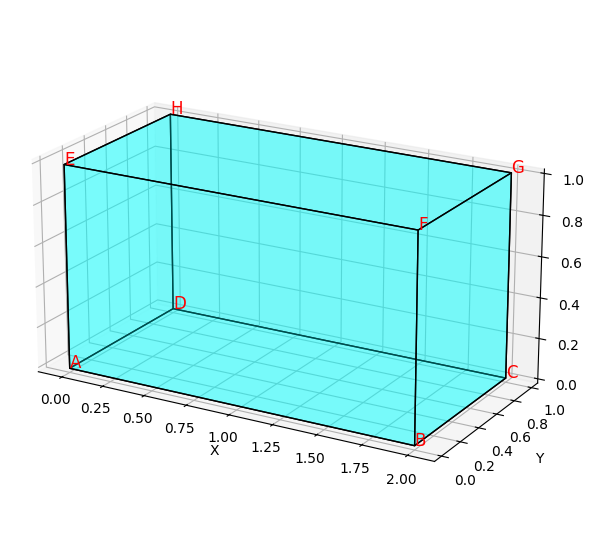

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

In [6]:
# 2. Нарисуйте параллелепипед в исходном положении

# Координаты вершин параллелепипеда (пример)
vertices = np.array([
    [0, 0, 0],  # A
    [2, 0, 0],  # B
    [2, 1, 0],  # C
    [0, 1, 0],  # D
    [0, 0, 1],  # E
    [2, 0, 1],  # F
    [2, 1, 1],  # G
    [0, 1, 1],  # H
])

def plot_parallelepiped(vertices, ax=None, color='cyan', alpha=0.3, edgecolor='k', show=True):
    # Грани параллелепипеда (по индексам вершин)
    faces = [
        [0, 1, 2, 3],  # низ
        [4, 5, 6, 7],  # верх
        [0, 1, 5, 4],  # бок
        [2, 3, 7, 6],  # бок
        [1, 2, 6, 5],  # бок
        [0, 3, 7, 4],  # бок
    ]
    if ax is None:
        fig = plt.figure(figsize=(7,7))
        ax = fig.add_subplot(111, projection='3d')
    poly3d = [[vertices[vert_id] for vert_id in face] for face in faces]
    ax.add_collection3d(Poly3DCollection(poly3d, facecolors=color, linewidths=1, edgecolors=edgecolor, alpha=alpha))
    # Подписи вершин
    for i, (x, y, z) in enumerate(vertices):
        ax.text(x, y, z, f'{chr(65+i)}', color='red', fontsize=12)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_box_aspect([np.ptp(vertices[:,0]), np.ptp(vertices[:,1]), np.ptp(vertices[:,2])])
    ax.view_init(elev=20, azim=-60, vertical_axis='z')  # Ось Oy вверх
    if show:
        plt.show()
    return ax

plot_parallelepiped(vertices)

In [9]:
# 3. Поворот на 90° вокруг оси Oy (матрица Эйлера вручную и через SciPy)

# Поворот на 90 градусов вокруг Oy
_, Ry, _ = rotation_matrices(90)
vertices_rot = vertices @ Ry.T

# С помощью SciPy
from scipy.spatial.transform import Rotation as R
rot = R.from_euler('y', 90, degrees=True)
vertices_rot_scipy = rot.apply(vertices)

# Проверка совпадения результатов
print("Максимальное различие между ручным и scipy:", np.max(np.abs(vertices_rot - vertices_rot_scipy)))

Максимальное различие между ручным и scipy: 3.2162452993532727e-16


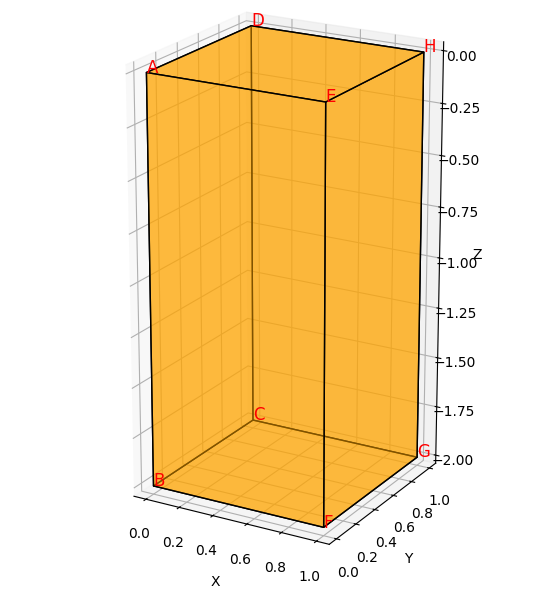

A: [0. 0. 0.]
B: [ 1.2246468e-16  0.0000000e+00 -2.0000000e+00]
C: [ 1.2246468e-16  1.0000000e+00 -2.0000000e+00]
D: [0. 1. 0.]
E: [1.000000e+00 0.000000e+00 6.123234e-17]
F: [ 1.  0. -2.]
G: [ 1.  1. -2.]
H: [1.000000e+00 1.000000e+00 6.123234e-17]


In [10]:
# Визуализация
plot_parallelepiped(vertices_rot, color='orange', alpha=0.5)

# Координаты вершин после поворота
for i, v in enumerate(vertices_rot):
    print(f"{chr(65+i)}: {v}")

Максимальное различие между ручным и scipy: 3.2162452993532727e-16


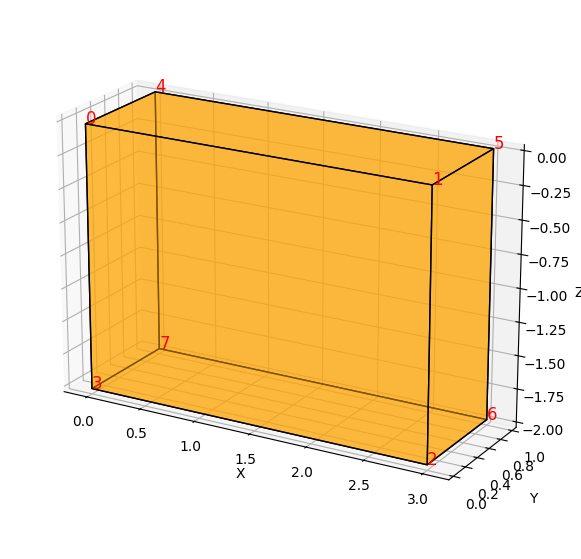

Координаты вершин после поворота вокруг Ox на -90°:
0: [0. 0. 0.]
1: [3. 0. 0.]
2: [ 3.0000000e+00  1.2246468e-16 -2.0000000e+00]
3: [ 0.0000000e+00  1.2246468e-16 -2.0000000e+00]
4: [0.000000e+00 1.000000e+00 6.123234e-17]
5: [3.000000e+00 1.000000e+00 6.123234e-17]
6: [ 3.  1. -2.]
7: [ 0.  1. -2.]


In [11]:
from scipy.spatial.transform import Rotation as R

# Пример координат исходного параллелепипеда (замените на ваши, если нужно)
vertices = np.array([
    [0, 0, 0],  # 0
    [3, 0, 0],  # 1
    [3, 2, 0],  # 2
    [0, 2, 0],  # 3
    [0, 0, 1],  # 4
    [3, 0, 1],  # 5
    [3, 2, 1],  # 6
    [0, 2, 1],  # 7
])

def rotation_matrices(angle_deg):
    angle = np.radians(angle_deg)
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(angle), -np.sin(angle)],
        [0, np.sin(angle),  np.cos(angle)]
    ])
    Ry = np.array([
        [ np.cos(angle), 0, np.sin(angle)],
        [0, 1, 0],
        [-np.sin(angle), 0, np.cos(angle)]
    ])
    Rz = np.array([
        [np.cos(angle), -np.sin(angle), 0],
        [np.sin(angle),  np.cos(angle), 0],
        [0, 0, 1]
    ])
    return Rx, Ry, Rz

def plot_parallelepiped(vertices, ax=None, color='cyan', alpha=0.3, edgecolor='k', show=True):
    faces = [
        [0, 1, 2, 3],  # низ
        [4, 5, 6, 7],  # верх
        [0, 1, 5, 4],  # бок
        [2, 3, 7, 6],  # бок
        [1, 2, 6, 5],  # бок
        [0, 3, 7, 4],  # бок
    ]
    if ax is None:
        fig = plt.figure(figsize=(7,7))
        ax = fig.add_subplot(111, projection='3d')
    poly3d = [[vertices[vert_id] for vert_id in face] for face in faces]
    ax.add_collection3d(Poly3DCollection(poly3d, facecolors=color, linewidths=1, edgecolors=edgecolor, alpha=alpha))
    for i, (x, y, z) in enumerate(vertices):
        ax.text(x, y, z, f'{i}', color='red', fontsize=12)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_box_aspect([np.ptp(vertices[:,0]), np.ptp(vertices[:,1]), np.ptp(vertices[:,2])])
    ax.view_init(elev=20, azim=-60, vertical_axis='z')
    if show:
        plt.show()
    return ax

# 1. Поворот вокруг Ox на -90° (ручная функция)
Rx, _, _ = rotation_matrices(-90)
vertices_rot = vertices @ Rx.T

# 2. Поворот через SciPy
rot = R.from_euler('x', -90, degrees=True)
vertices_rot_scipy = rot.apply(vertices)

# 3. Проверка совпадения
print("Максимальное различие между ручным и scipy:", np.max(np.abs(vertices_rot - vertices_rot_scipy)))

# 4. Визуализация
plot_parallelepiped(vertices_rot, color='orange', alpha=0.5)

# 5. Координаты вершин после поворота
print("Координаты вершин после поворота вокруг Ox на -90°:")
for i, v in enumerate(vertices_rot):
    print(f"{i}: {v}")

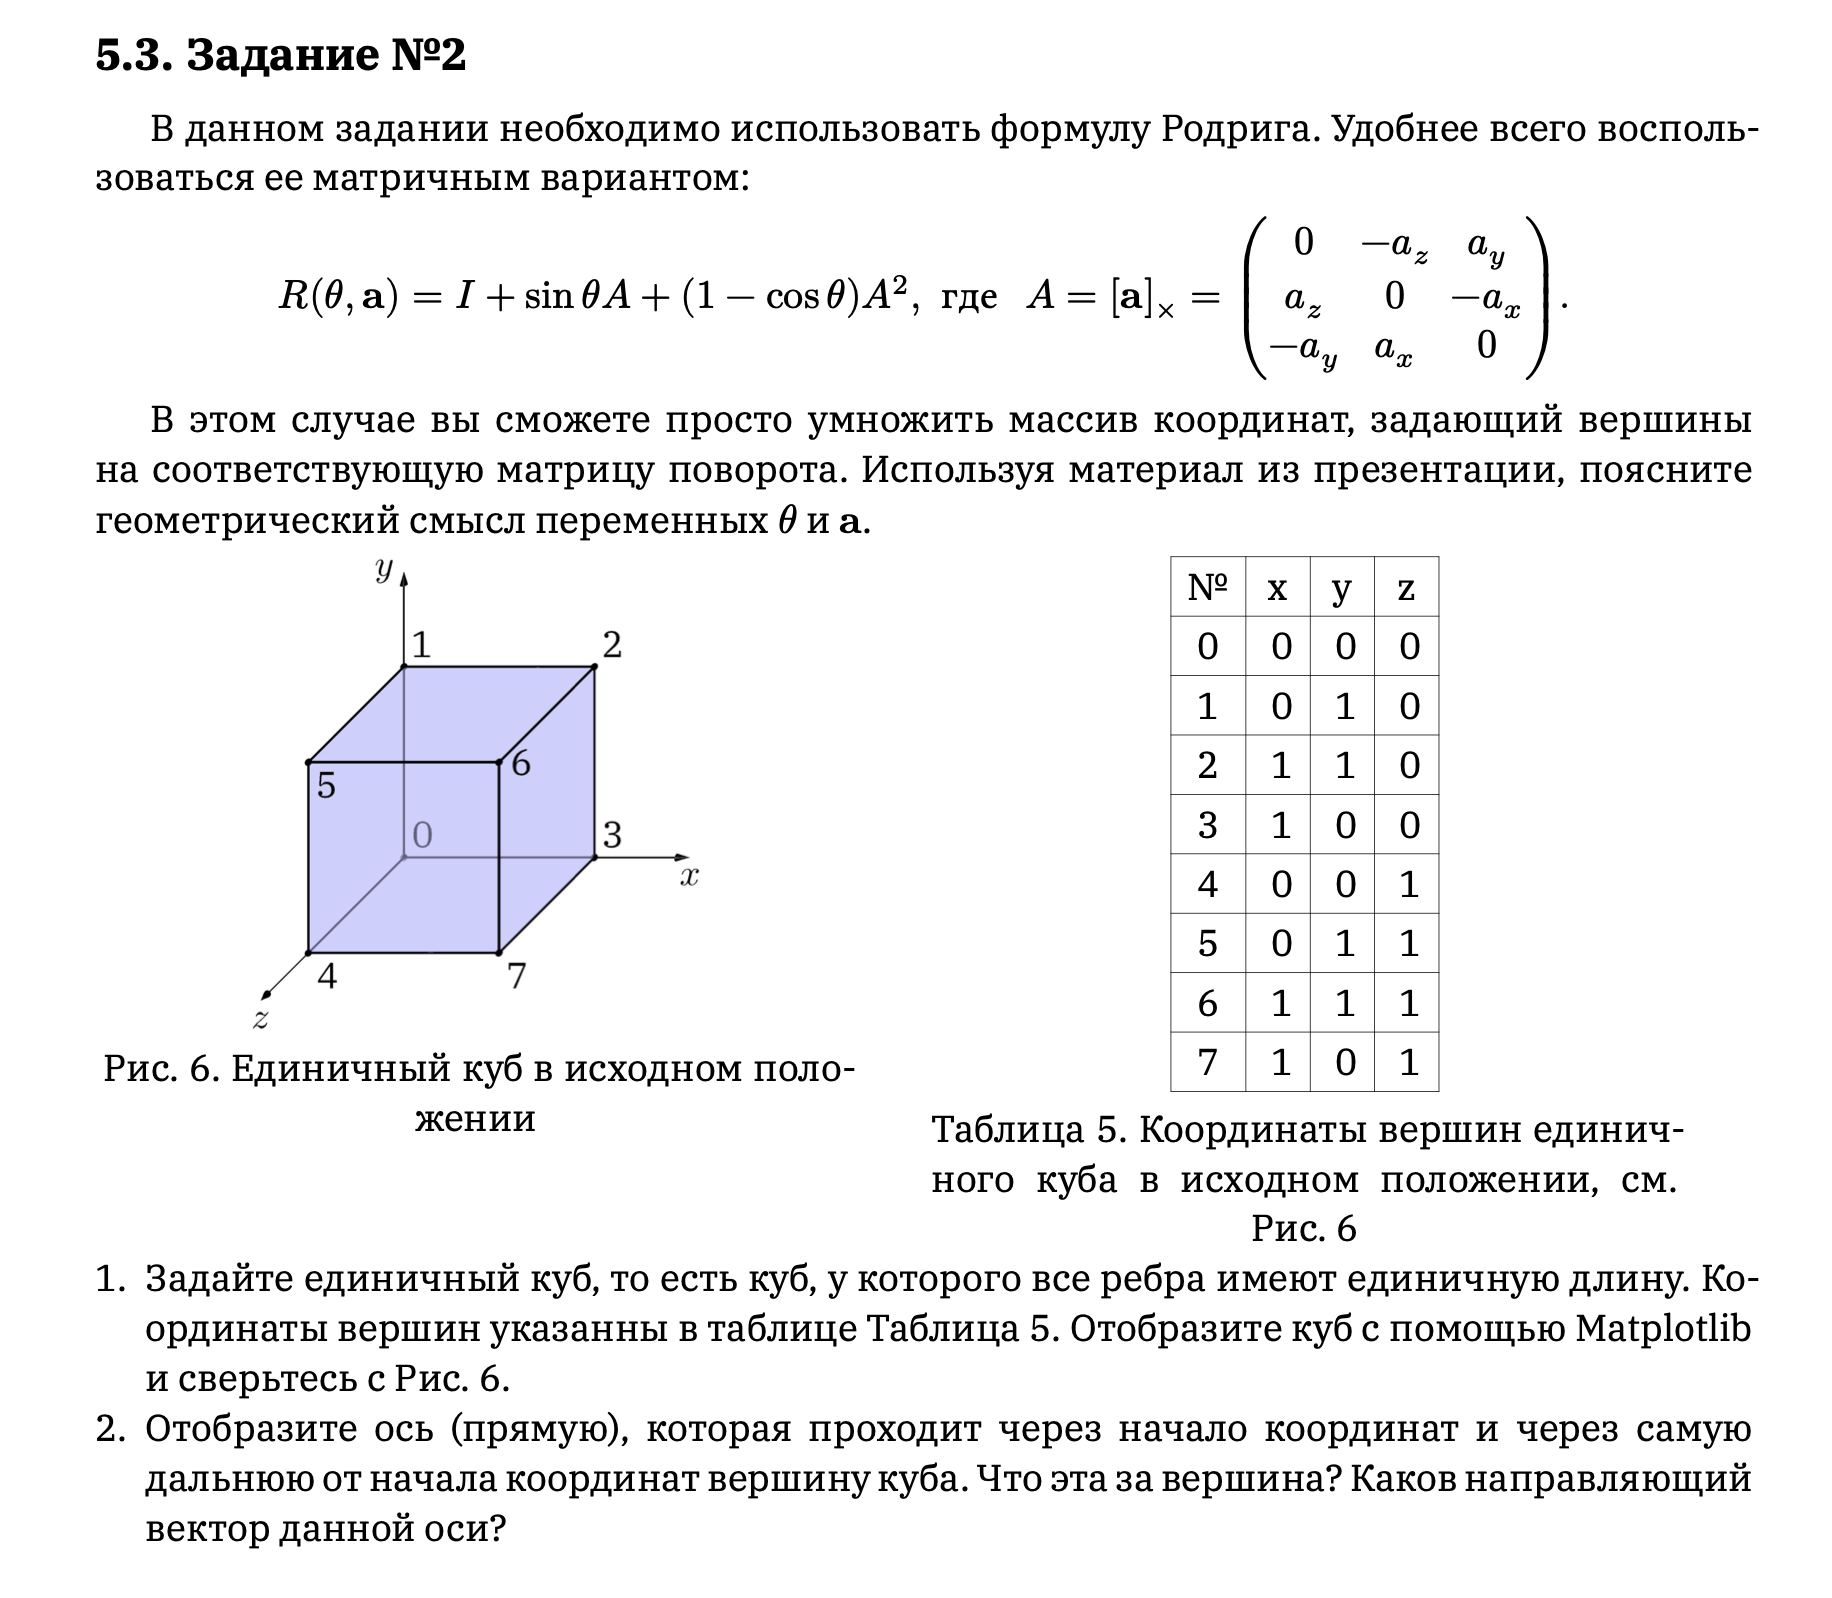
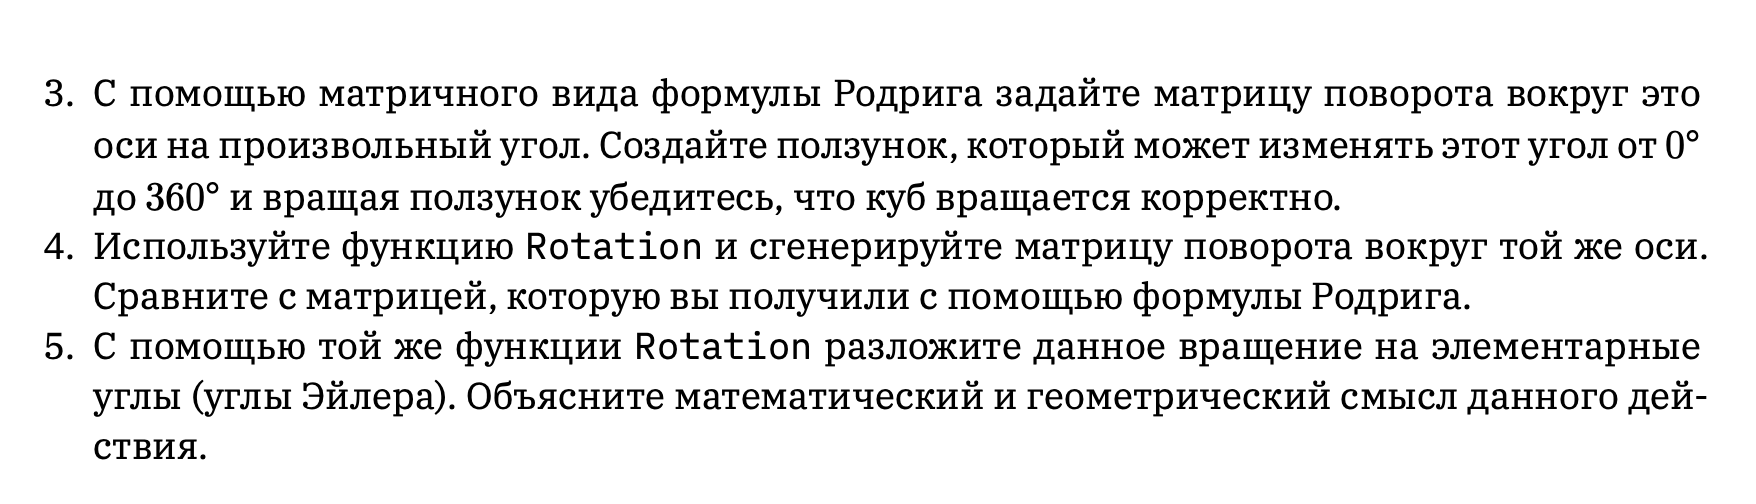

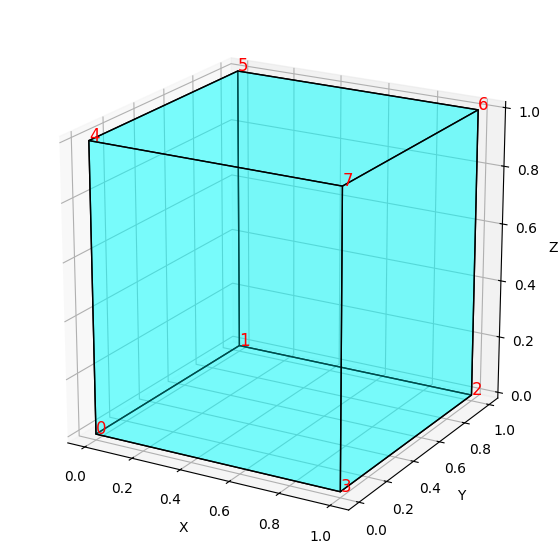

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

In [12]:
# 1. Задаём единичный куб
# Вершины куба (таблица 5)
cube_vertices = np.array([
    [0, 0, 0],  # 0
    [0, 1, 0],  # 1
    [1, 1, 0],  # 2
    [1, 0, 0],  # 3
    [0, 0, 1],  # 4
    [0, 1, 1],  # 5
    [1, 1, 1],  # 6
    [1, 0, 1],  # 7
])

def plot_cube(vertices, ax=None, color='cyan', alpha=0.3, edgecolor='k', show=True):
    faces = [
        [0, 1, 2, 3],  # низ
        [4, 5, 6, 7],  # верх
        [0, 1, 5, 4],  # бок
        [2, 3, 7, 6],  # бок
        [1, 2, 6, 5],  # бок
        [0, 3, 7, 4],  # бок
    ]
    if ax is None:
        fig = plt.figure(figsize=(7,7))
        ax = fig.add_subplot(111, projection='3d')
    poly3d = [[vertices[vert_id] for vert_id in face] for face in faces]
    ax.add_collection3d(Poly3DCollection(poly3d, facecolors=color, linewidths=1, edgecolors=edgecolor, alpha=alpha))
    for i, (x, y, z) in enumerate(vertices):
        ax.text(x, y, z, f'{i}', color='red', fontsize=12)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_box_aspect([np.ptp(vertices[:,0]), np.ptp(vertices[:,1]), np.ptp(vertices[:,2])])
    ax.view_init(elev=20, azim=-60, vertical_axis='z')
    if show:
        plt.show()
    return ax

plot_cube(cube_vertices)

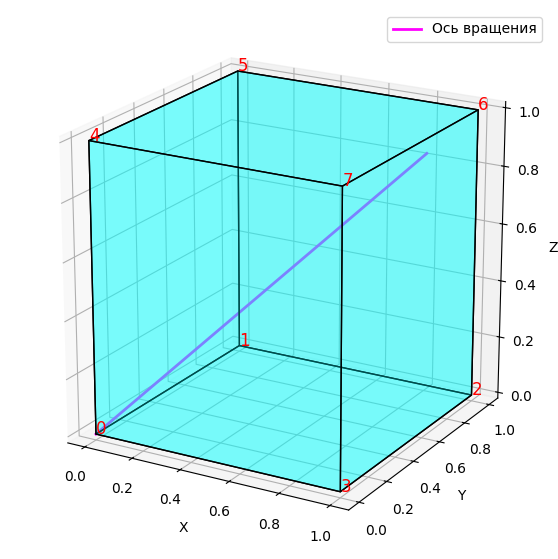

In [13]:
# 2. Ось, проходящая через начало координат и самую дальнюю вершину

# Самая дальняя вершина: [1, 1, 1] (вершина 6)
# Направляющий вектор оси: a = (1, 1, 1)

def plot_axis(ax, a, length=2, color='magenta'):
    a = np.array(a) / np.linalg.norm(a)
    ax.plot([0, a[0]*length], [0, a[1]*length], [0, a[2]*length], color=color, linewidth=2, label='Ось вращения')
    ax.legend()

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')
plot_cube(cube_vertices, ax=ax, show=False)
plot_axis(ax, [1,1,1], length=1.5)
plt.show()

In [14]:
# 3. Формула Родрига (матрица поворота вокруг оси a на угол θ)

def rodrigues_matrix(axis, theta_deg):
    """
    axis: направляющий вектор (любая длина)
    theta_deg: угол в градусах
    """
    theta = np.radians(theta_deg)
    a = np.array(axis, dtype=float)
    a = a / np.linalg.norm(a)
    ax, ay, az = a
    A = np.array([
        [0, -az, ay],
        [az, 0, -ax],
        [-ay, ax, 0]
    ])
    I = np.eye(3)
    R = I + np.sin(theta)*A + (1 - np.cos(theta))*(A @ A)
    return R

In [17]:
# 4. Вращение куба с помощью Родрига и сравнение с SciPy

from ipywidgets import interact, FloatSlider

def rotate_and_plot_cube(theta_deg=0.0):
    axis = [1,1,1]
    R_rod = rodrigues_matrix(axis, theta_deg)
    cube_rot = cube_vertices @ R_rod.T

    # SciPy
    rot = R.from_rotvec(np.radians(theta_deg) * np.array(axis)/np.linalg.norm(axis))
    cube_rot_scipy = rot.apply(cube_vertices)
    diff = np.max(np.abs(cube_rot - cube_rot_scipy))

    fig = plt.figure(figsize=(7,7))
    ax = fig.add_subplot(111, projection='3d')
    plot_cube(cube_rot, ax=ax, color='orange', alpha=0.5, show=False)
    plot_axis(ax, axis, length=1.5)
    plt.title(f"Куб, повернутый на {theta_deg:.1f}° вокруг оси [1,1,1]\nМакс. разница с SciPy: {diff:.2e}")
    plt.show()

    # Координаты вершин
    print("Координаты вершин после поворота:")
    for i, v in enumerate(cube_rot):
        print(f"{i}: {v}")

interact(
    rotate_and_plot_cube,
    theta_deg=FloatSlider(value=0.0, min=0.0, max=360.0, step=1.0, description='θ (°)')
)

interactive(children=(FloatSlider(value=0.0, description='θ (°)', max=360.0, step=1.0), Output()), _dom_classe…

<function __main__.rotate_and_plot_cube(theta_deg=0.0)>

In [20]:
# 5. Разложение вращения на элементарные углы (углы Эйлера)

# Пусть у нас есть ось вращения и угол
axis = np.array([1, 1, 1])
axis = axis / np.linalg.norm(axis)
theta_deg = 120

# Создаём объект вращения
rot = R.from_rotvec(np.radians(theta_deg) * axis)

# Получаем углы Эйлера в разных системах (например, XYZ, ZYX)
euler_xyz = rot.as_euler('xyz', degrees=True)
euler_zyx = rot.as_euler('zyx', degrees=True)
euler_yzx = rot.as_euler('yzx', degrees=True)

print("Углы Эйлера (xyz, градусы):", euler_xyz)
print("Углы Эйлера (zyx, градусы):", euler_zyx)
print("Углы Эйлера (yzx, градусы):", euler_yzx)

Углы Эйлера (xyz, градусы): [90.  0. 90.]
Углы Эйлера (zyx, градусы): [90. 90. -0.]
Углы Эйлера (yzx, градусы): [90.  0. 90.]


/Users/artyem.petrov/miniconda3/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3639: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  if await self.run_code(code, result, async_=asy):


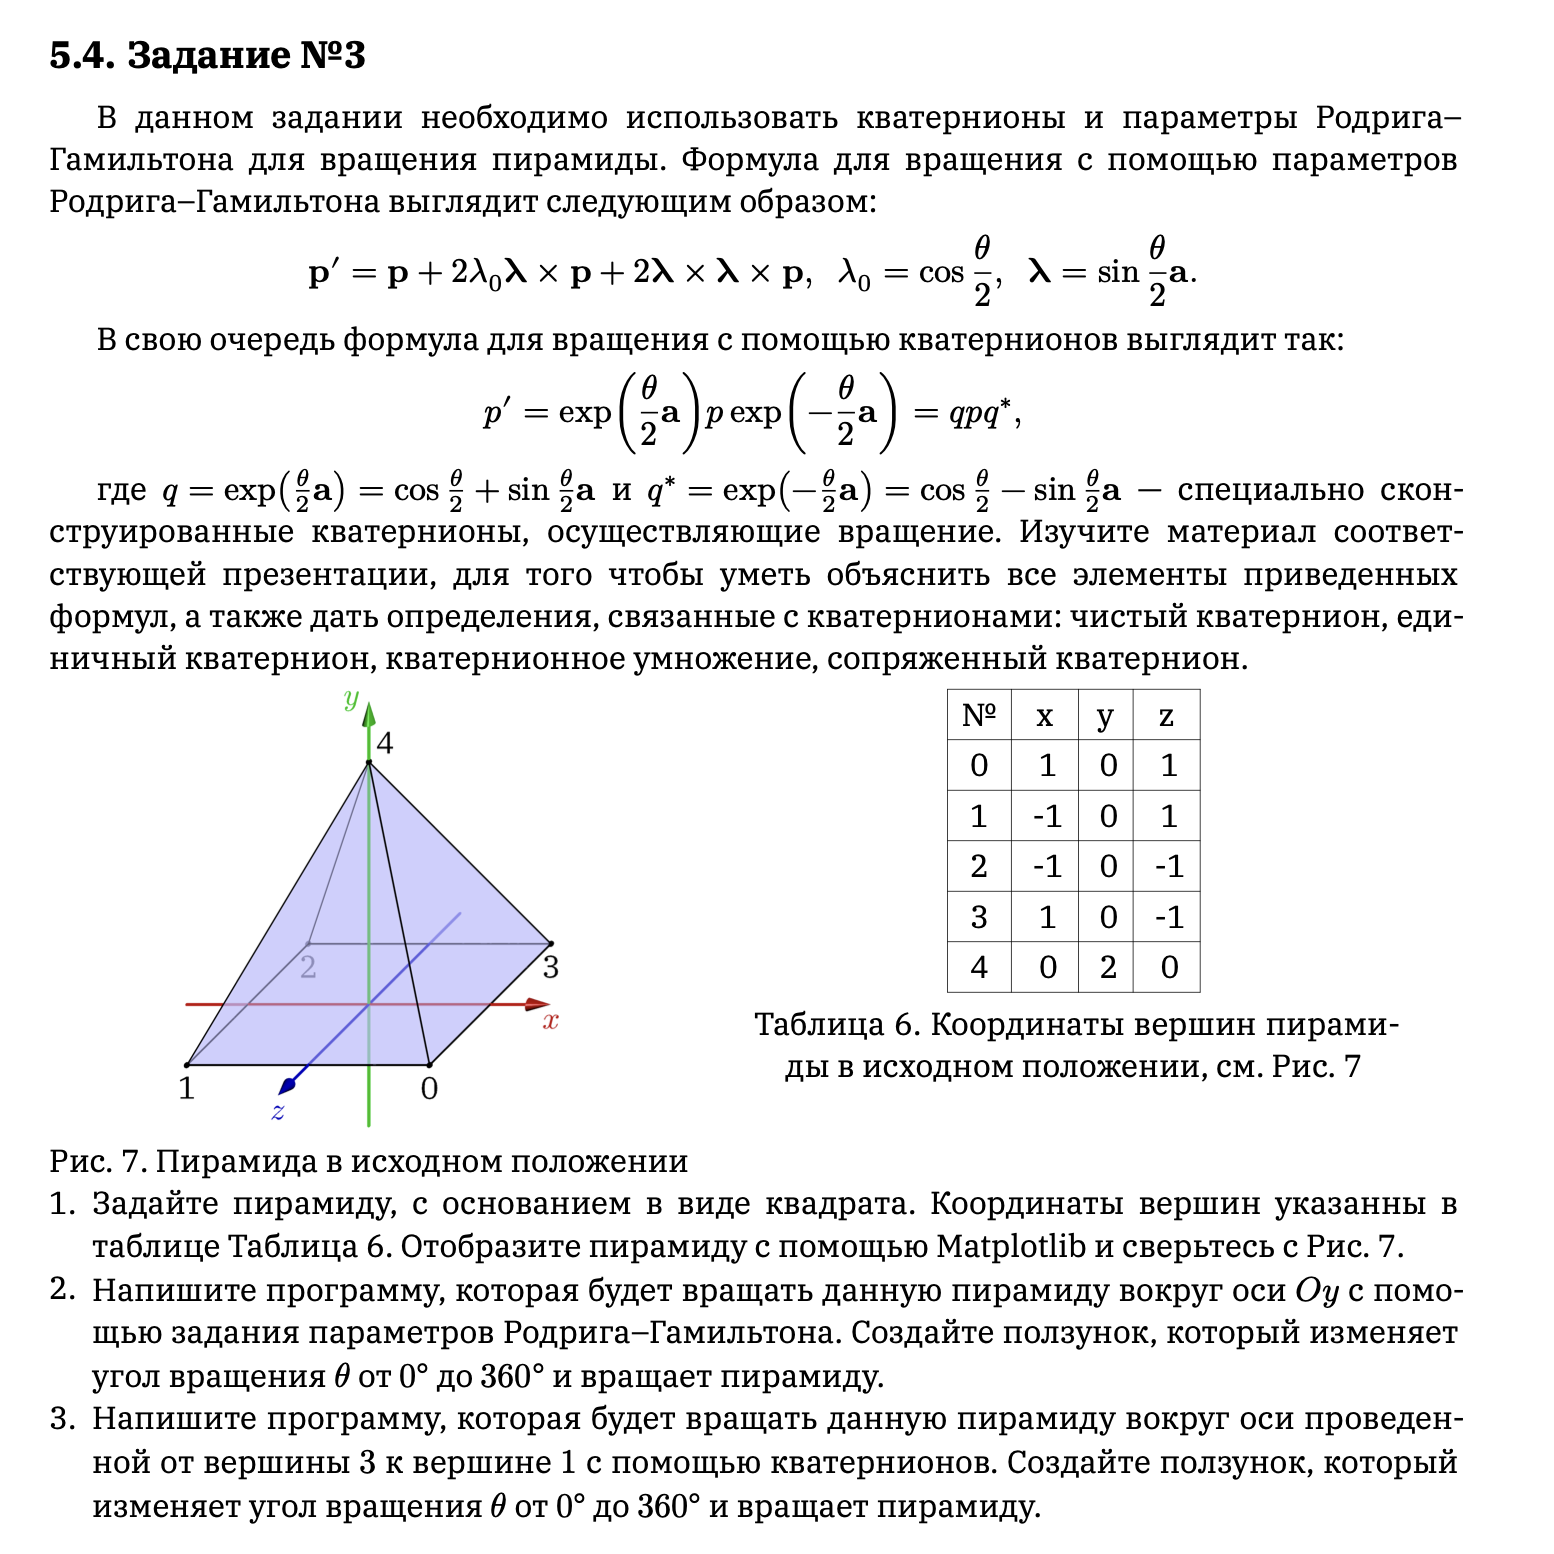

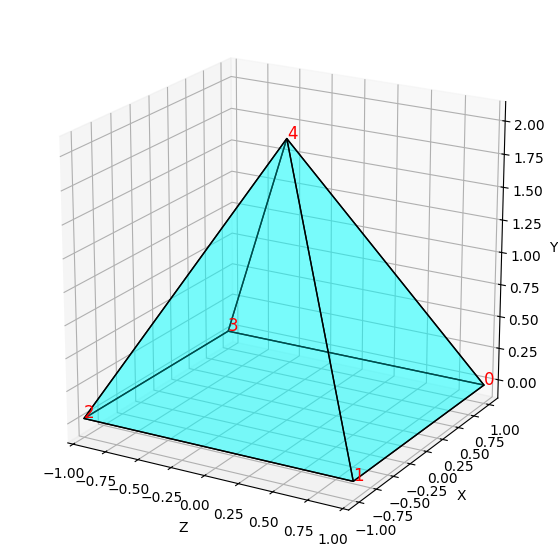

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

In [24]:
# Вершины пирамиды (таблица 6)

pyramid_vertices = np.array([
    [1, 0, 1],
    [-1, 0, 1],
    [-1, 0, -1],
    [1, 0, -1],
    [0, 2, 0]
])

def plot_pyramid(vertices, ax=None, color='cyan', alpha=0.3, edgecolor='k', show=True, vertical_axis='y'):
    faces = [
        [0, 1, 2, 3],
        [0, 1, 4],
        [1, 2, 4],
        [2, 3, 4],
        [3, 0, 4]
    ]
    if ax is None:
        fig = plt.figure(figsize=(7,7))
        ax = fig.add_subplot(111, projection='3d')
    poly3d = [[vertices[vert_id] for vert_id in face] for face in faces]
    ax.add_collection3d(Poly3DCollection(poly3d, facecolors=color, linewidths=1, edgecolors=edgecolor, alpha=alpha))
    for i, (x, y, z) in enumerate(vertices):
        ax.text(x, y, z, f'{i}', color='red', fontsize=12)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_box_aspect([np.ptp(vertices[:,0]), np.ptp(vertices[:,1]), np.ptp(vertices[:,2])])
    # Set which axis is vertical
    ax.view_init(elev=20, azim=-60, vertical_axis=vertical_axis)
    if show:
        plt.show()
    return ax

# Y axis is vertical
plot_pyramid(pyramid_vertices, vertical_axis='y')

In [26]:
# 2. Вращение вокруг Oy с помощью Родрига–Гамильтона
from ipywidgets import interact, FloatSlider

def rodrigues_hamilton_matrix(axis, theta_deg):
    theta = np.radians(theta_deg)
    a = np.array(axis, dtype=float)
    a = a / np.linalg.norm(a)
    ax, ay, az = a
    A = np.array([
        [0, -az, ay],
        [az, 0, -ax],
        [-ay, ax, 0]
    ])
    I = np.eye(3)
    R = I + np.sin(theta)*A + (1 - np.cos(theta))*(A @ A)
    return R

def rotate_pyramid_rodrigues(theta_deg=0.0):
    axis = [0, 1, 0]  # Oy
    R = rodrigues_hamilton_matrix(axis, theta_deg)
    pyramid_rot = pyramid_vertices @ R.T

    fig = plt.figure(figsize=(7,7))
    ax = fig.add_subplot(111, projection='3d')
    plot_pyramid(pyramid_rot, ax=ax, color='orange', alpha=0.5, show=False)
    # Ось вращения
    ax.plot([0, 0], [0, 2.5], [0, 0], color='magenta', linewidth=2, label='Ось Oy')
    ax.legend()
    plt.title(f"Пирамида, повернутая на {theta_deg:.1f}° вокруг Oy")
    plt.show()

interact(
    rotate_pyramid_rodrigues,
    theta_deg=FloatSlider(value=0.0, min=0.0, max=360.0, step=1.0, description='θ (°)')
)

interactive(children=(FloatSlider(value=0.0, description='θ (°)', max=360.0, step=1.0), Output()), _dom_classe…

<function __main__.rotate_pyramid_rodrigues(theta_deg=0.0)>

In [27]:
# 3. Вращение вокруг оси из вершины 3 в вершину 1 с помощью кватернионов

def quaternion_from_axis_angle(axis, theta_deg):
    theta = np.radians(theta_deg)
    axis = np.array(axis, dtype=float)
    axis = axis / np.linalg.norm(axis)
    q0 = np.cos(theta/2)
    q_vec = np.sin(theta/2) * axis
    return np.concatenate([[q0], q_vec])

def quaternion_conjugate(q):
    q0, qv = q[0], q[1:]
    return np.concatenate([[q0], -qv])

def quaternion_mult(q1, q2):
    w1, x1, y1, z1 = q1
    w2, x2, y2, z2 = q2
    w = w1*w2 - x1*x2 - y1*y2 - z1*z2
    x = w1*x2 + x1*w2 + y1*z2 - z1*y2
    y = w1*y2 - x1*z2 + y1*w2 + z1*x2
    z = w1*z2 + x1*y2 - y1*x2 + z1*w2
    return np.array([w, x, y, z])

def rotate_vector_by_quaternion(v, q):
    v_q = np.concatenate([[0], v])
    q_conj = quaternion_conjugate(q)
    v_rot = quaternion_mult(quaternion_mult(q, v_q), q_conj)
    return v_rot[1:]

def rotate_pyramid_quaternion(theta_deg=0.0):
    # Ось: из вершины 3 в вершину 1
    p3 = pyramid_vertices[3]
    p1 = pyramid_vertices[1]
    axis = p1 - p3
    axis = axis / np.linalg.norm(axis)
    q = quaternion_from_axis_angle(axis, theta_deg)
    # Вращаем относительно начала координат
    pyramid_rot = np.array([rotate_vector_by_quaternion(v, q) for v in pyramid_vertices])

    fig = plt.figure(figsize=(7,7))
    ax = fig.add_subplot(111, projection='3d')
    plot_pyramid(pyramid_rot, ax=ax, color='lime', alpha=0.5, show=False)
    # Ось вращения
    start = p3
    end = p1
    ax.plot([start[0], end[0]], [start[1], end[1]], [start[2], end[2]], color='magenta', linewidth=2, label='Ось 3→1')
    ax.legend()
    plt.title(f"Пирамида, повернутая на {theta_deg:.1f}° вокруг оси 3→1 (кватернион)")
    plt.show()

interact(
    rotate_pyramid_quaternion,
    theta_deg=FloatSlider(value=0.0, min=0.0, max=360.0, step=1.0, description='θ (°)')
)

interactive(children=(FloatSlider(value=0.0, description='θ (°)', max=360.0, step=1.0), Output()), _dom_classe…

<function __main__.rotate_pyramid_quaternion(theta_deg=0.0)>

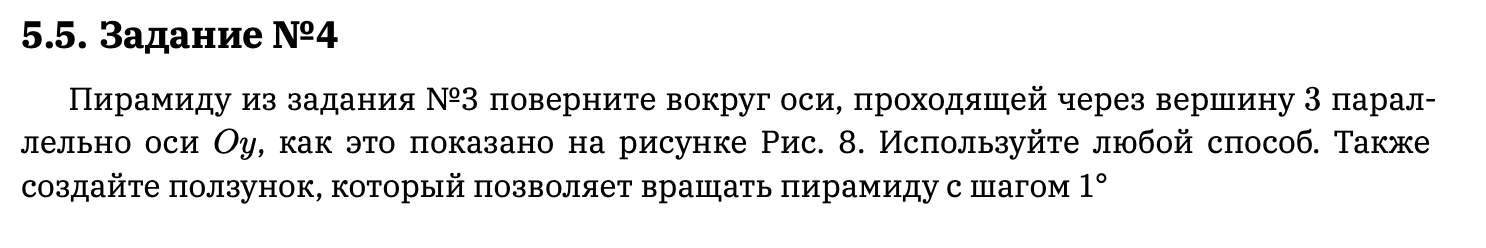

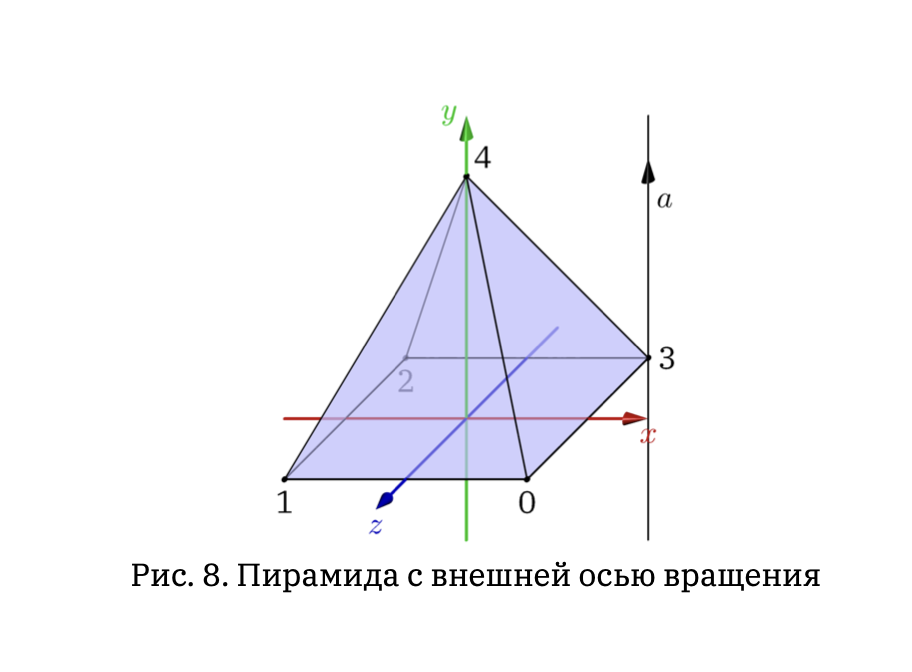

In [29]:
from ipywidgets import IntSlider

def rodrigues_matrix(axis, theta_deg):
    theta = np.radians(theta_deg)
    a = np.array(axis, dtype=float)
    a = a / np.linalg.norm(a)
    ax, ay, az = a
    A = np.array([
        [0, -az, ay],
        [az, 0, -ax],
        [-ay, ax, 0]
    ])
    I = np.eye(3)
    R = I + np.sin(theta)*A + (1 - np.cos(theta))*(A @ A)
    return R

def rotate_pyramid_around_axis(theta_deg=0):
    # Ось: параллельна Oy, проходит через вершину 3
    p3 = pyramid_vertices[3]
    axis = [0, 1, 0]
    R = rodrigues_matrix(axis, theta_deg)
    # Переносим пирамиду так, чтобы вершина 3 стала началом координат
    shifted = pyramid_vertices - p3
    # Вращаем
    rotated = shifted @ R.T
    # Возвращаем обратно
    rotated = rotated + p3

    fig = plt.figure(figsize=(7,7))
    ax = fig.add_subplot(111, projection='3d')
    plot_pyramid(rotated, ax=ax, color='orange', alpha=0.5, show=False)
    # Ось вращения (через вершину 3, параллельно Oy)
    y_line = np.linspace(-1, 3, 2)
    x0, z0 = p3[0], p3[2]
    ax.plot([x0, x0], y_line, [z0, z0], color='magenta', linewidth=2, label='Ось через 3 || Oy')
    ax.legend()
    plt.title(f"Вращение пирамиды вокруг оси через вершину 3 || Oy\nУгол: {theta_deg}°")
    plt.show()

interact(
    rotate_pyramid_around_axis,
    theta_deg=IntSlider(value=0, min=0, max=360, step=1, description='θ (°)')
)

interactive(children=(IntSlider(value=0, description='θ (°)', max=360), Output()), _dom_classes=('widget-inter…

<function __main__.rotate_pyramid_around_axis(theta_deg=0)>